This notebook requires that the constraint and the numb_sites_region are run before

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

motif_length = 3
from estimating_ud.config import results_dir

TABLES = results_dir("tables")

colorblind_palette = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7"]


# Trinucleotide model

In [ ]:
Constraint = pd.read_csv(TABLES / "trinuc_constraint_mean_sem.csv")
numb_sites = pd.read_csv(TABLES / "length_perregion.csv")
UT = pd.read_csv(TABLES / f"UT_perregion_motiflength{motif_length}.csv")
Mut_rates = pd.read_csv(TABLES / f"average_mutrates_motiflength{motif_length}_mean_sem.csv")

In [ ]:
Constraint = Constraint[Constraint.iloc[:, 0] == "mean"].reset_index(drop=True)
Constraint = Constraint.iloc[:, 1:3].copy()
Constraint.columns = ["Region", "Constraint"]
Constraint

,Region,Constraint
0,cds,0.624297
1,distalIG,0.053091
2,introns3UTR,0.387324
3,introns5UTR,0.381858
4,intronsAR,0.106581
5,introns_nonUTR,0.200553
6,proximal3IG,0.144786
7,proximal5IG,0.144977


In [ ]:
numb_sites = numb_sites.iloc[:, 1:4].copy()
numb_sites

,Region,total_numb_sites,fraction_of_total_sites
0,cds,32311773,0.020346
1,distalIG,218153499,0.137366
2,introns3UTR,6693941,0.004215
3,introns5UTR,6727706,0.004236
4,intronsAR,596828432,0.375810
5,introns_nonUTR,635773378,0.400332
6,proximal3IG,45854232,0.028873
7,proximal5IG,45770549,0.028821


In [ ]:
UT = UT.iloc[:, 1:4].copy()
UT

,Region,UT,UT_fraction
0,cds,1.195432,0.028087
1,distalIG,5.418376,0.127307
2,introns3UTR,0.232706,0.005468
3,introns5UTR,0.231799,0.005446
4,intronsAR,16.284617,0.382614
5,introns_nonUTR,16.700769,0.392392
6,proximal3IG,1.249524,0.029358
7,proximal5IG,1.248207,0.029327


In [ ]:
Mut_rates = Mut_rates[Mut_rates.iloc[:, 0] == "mean"].reset_index(drop=True)
Mut_rates = Mut_rates.iloc[:, 1:3].copy()
Mut_rates.columns = ["Region", "Mut_rates"]
Mut_rates

,Region,Mut_rates
0,cds,1.855308e-08
1,distalIG,1.267585e-08
2,introns3UTR,1.747793e-08
3,introns5UTR,1.734119e-08
4,intronsAR,1.376711e-08
5,introns_nonUTR,1.337099e-08
6,proximal3IG,1.380438e-08
7,proximal5IG,1.382104e-08


In [ ]:
# Constraint and Mut_rates were reduced to their mean rows in the cells above
alldata_df = (
    Constraint
    .merge(numb_sites, on="Region")
    .merge(UT, on="Region")
    .merge(Mut_rates, on="Region")
)

alldata_df["Udregion"] = (
    alldata_df["Constraint"]
    * alldata_df["UT"]
).clip(lower=0)

alldata_df["Udregion_fraction"] = (
    alldata_df["Udregion"]/alldata_df["Udregion"].sum()
).clip(lower=0)

alldata_df

,Region,Constraint,total_numb_sites,fraction_of_total_sites,UT,UT_fraction,Mut_rates,Udregion,Udregion_fraction
0,cds,0.624297,32311773,0.020346,1.195432,0.028087,1.855308e-08,0.746304,0.112066
1,distalIG,0.053091,218153499,0.137366,5.418376,0.127307,1.267585e-08,0.287669,0.043197
2,introns3UTR,0.387324,6693941,0.004215,0.232706,0.005468,1.747793e-08,0.090133,0.013534
3,introns5UTR,0.381858,6727706,0.004236,0.231799,0.005446,1.734119e-08,0.088514,0.013291
4,intronsAR,0.106581,596828432,0.375810,16.284617,0.382614,1.376711e-08,1.735630,0.260624
5,introns_nonUTR,0.200553,635773378,0.400332,16.700769,0.392392,1.337099e-08,3.349386,0.502948
6,proximal3IG,0.144786,45854232,0.028873,1.249524,0.029358,1.380438e-08,0.180913,0.027166
7,proximal5IG,0.144977,45770549,0.028821,1.248207,0.029327,1.382104e-08,0.180962,0.027173


In [ ]:
#Fraction of the total haploid genome sampled
sum(alldata_df["total_numb_sites"])/(3.2*10**9)

0.496285471875

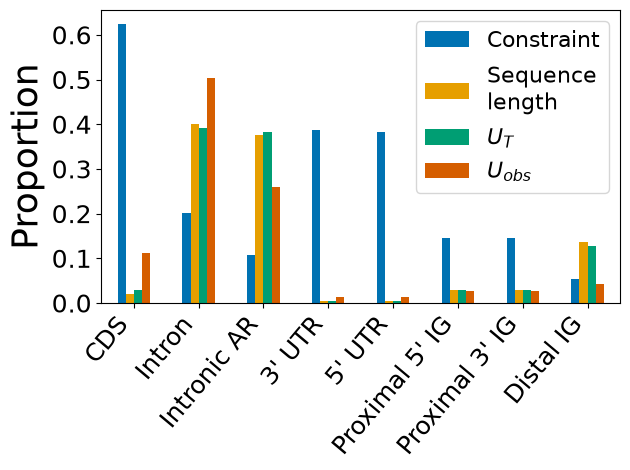

In [ ]:
name_map = dict(zip(
    ["cds", "introns_nonUTR", "intronsAR", "introns3UTR", "introns5UTR",
     "proximal5IG", "proximal3IG", "distalIG"],
    ["CDS", "Intron", "Intronic AR", "3' UTR", "5' UTR",
     "Proximal 5' IG", "Proximal 3' IG", "Distal IG"]
))
alldata_df = (
    alldata_df.set_index("Region")
    .loc[list(name_map)]
    .reset_index()
)

labelfontsize = 26
ticksfontsize = 18
legendfontsize = 16

ax = alldata_df.plot(
    x='Region',
    y=['Constraint', 'fraction_of_total_sites', 'UT_fraction', 'Udregion_fraction'],
    kind='bar',
    color=[colorblind_palette[0], colorblind_palette[1], colorblind_palette[2], colorblind_palette[3]],
)
plt.ylabel('Proportion', fontsize=labelfontsize)
plt.yticks(fontsize=ticksfontsize)
ax.set_xticklabels(
    alldata_df["Region"].map(name_map),
    rotation=50,
    ha="right",
    fontsize=ticksfontsize
)
plt.legend(['Constraint', 'Sequence\nlength', r'$U_T$', r'$U_{obs}$'], fontsize=legendfontsize)
plt.xlabel('')
plt.tight_layout()

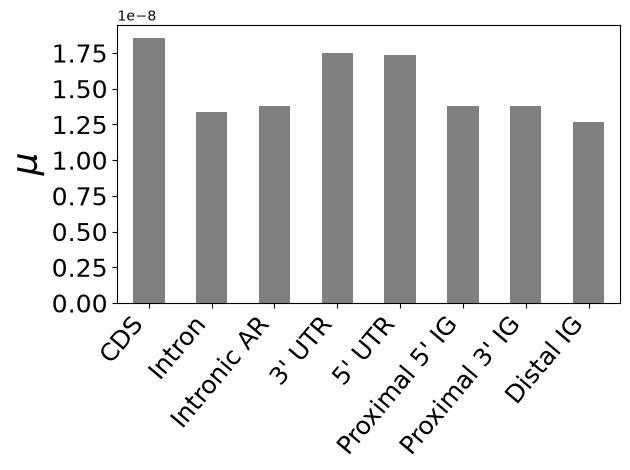

In [ ]:
name_map = dict(zip(
    ["cds", "introns_nonUTR", "intronsAR", "introns3UTR", "introns5UTR",
     "proximal5IG", "proximal3IG", "distalIG"],
    ["CDS", "Intron", "Intronic AR", "3' UTR", "5' UTR",
     "Proximal 5' IG", "Proximal 3' IG", "Distal IG"]
))
alldata_df = (
    alldata_df.set_index("Region")
    .loc[list(name_map)]
    .reset_index()
)

labelfontsize = 26
ticksfontsize = 18

ax = alldata_df.plot(
    x='Region',
    y='Mut_rates',
    kind='bar',
    color='gray',
    legend=False,
)
plt.ylabel(r'$\mu$', fontsize=labelfontsize)
plt.yticks(fontsize=ticksfontsize)
ax.set_xticklabels(
    alldata_df["Region"].map(name_map),
    rotation=50,
    ha="right",
    fontsize=ticksfontsize
)
plt.xlabel('')
plt.tight_layout()

In [ ]:
Ud = alldata_df["Udregion"].sum()
Ud

np.float64(6.659511117443033)

In [ ]:
alldata_df.loc[
    alldata_df["Region"].isin(["intronsAR", "introns_nonUTR", "introns3UTR", "introns5UTR"]),
    "Udregion_fraction"
].sum()

np.float64(0.7903978336015699)